# Project SD-186: Synthetic Loan Portfolio Data Generator
**Domain:** Banking & Finance | Universal/Commercial Bank (Philippine Market)
**Regulatory Anchors:** BSP Circular No. 1011 / PFRS 9 / Basel III | **Currency:** Philippine Peso (PHP, ₱)
**Author / Risk Analyst:** Eskwelabs Data Innovation Fellowship

---

## Executive Summary & Workflow Objectives
This notebook implements the complete 8-stage topological Directed Acyclic Graph (DAG) for **Project SD-186**:
1. **Stage 0 (Internal Macro Driver):** Monthly AR(1) latent stress index $Z_{macro}(t)$, BSP Overnight RRP rate $r_{BSP}(t)$, headline inflation $\pi(t)$, and unemployment rate $u(t)$ with an inflationary/tightening shock at $t \in [10, 20]$.
2. **Stage 1 (Borrowers):** Demographics, regional weighting, employment categories, stated income, and unobserved latent traits ($U_{resilience}, W_{informal\_debt}$ with $\rho = -0.35$).
3. **Stage 2 (CreditScores):** Longitudinal quarterly bureau scores with ~6.0% MAR missingness, credit utilization, and credit inquiries.
4. **Stage 3 & 4 (Loans & Collateral):** Origination contracts across 4 distinct products (Personal, Auto, Housing, SME Working Capital) with underwriting principal increments, fixed/floating rate structures, chattel/REM collateral, valuation drift, and forced-sale haircuts.
5. **Stages 5, 6, 7 (Servicing, Cash Flows & Delinquency):** Vectorized monthly simulation across 42 months (6-month warm-up $t \in [-6, -1]$ and 36-month observation $t \in [0, 35]$), tracking payment waterfalls, delinquency roll rates, prepayment mortality (SMM/CPR), collateral workouts, and IFRS 9 staging (Stage 1, Stage 2 SICR, Stage 3 Default).
6. **Verification & Scrub:** Pre-export integrity assertions (PK/FK/non-negative balances), omitted-variable scrub (stripping $U, W, Z_{macro}$ and internal helpers), and evaluation of `FLAG-01` through `FLAG-05` calibration metrics.

### 1. Environment Setup & Configuration
Locking random seed `SEED = 42`, time horizons (`T_WARMUP = 6`, `T_OBS = 36`), and importing modular functions from `src/`.

In [1]:
# Environment Setup & Google Colab / Drive Auto-Mount
import os
import sys
from pathlib import Path

try:
    from IPython.display import display
except ImportError:
    def display(df):
        print(df.to_string() if hasattr(df, 'to_string') else df)

# Detect Google Colab environment and auto-mount Google Drive if present
IN_COLAB = 'google.colab' in sys.modules
if IN_COLAB:
    try:
        from google.colab import drive
        if not Path('/content/drive').exists():
            drive.mount('/content/drive')
            print('[Colab] Google Drive mounted successfully at /content/drive')
    except Exception as e:
        print(f'[Colab] Google Drive notice: {e}')

    colab_candidates = [
        Path('/content/drive/MyDrive/sd186-loan-portfolio'),
        Path('/content/drive/MyDrive/SD-186_Loan_Portfolio'),
        Path('/content/drive/MyDrive/SD-186_Notebook'),
        Path('/content/drive/Shareddrives/sd186-loan-portfolio'),
        Path('/content/sd186-loan-portfolio'),
        Path('/content')
    ]
    for p in colab_candidates:
        if (p / 'src').exists() or (p / 'data').exists():
            os.chdir(p)
            print(f'[Colab] Set working directory to: {p}')
            break

# Auto-detect project root and add to sys.path (works seamlessly locally and in Colab)
project_root = Path.cwd()
for candidate in [project_root, project_root.parent, project_root / 'sd186-loan-portfolio', project_root / 'SD-186_Notebook']:
    if (candidate / 'src' / 'config.py').exists() or (candidate / 'data' / 'raw_export').exists():
        project_root = candidate.resolve()
        break

os.chdir(project_root)
if str(project_root) not in sys.path:
    sys.path.insert(0, str(project_root))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from src import config, generators, validators

# Verify locked parameters
print(f'Project Root: {project_root}')
print(f'Locked SEED: {config.SEED}')
print(f'Horizon: {config.T_WARMUP} warmup mos (t in [-6, -1]) + {config.T_OBS} obs mos (t in [0, 35]) = {config.T_TOTAL} total mos')
print(f'Default Borrower Scale: {config.DEFAULT_N_BORROWERS:,} (Smoke test scale: {config.SMOKE_TEST_N_BORROWERS:,})')

Project Root: C:\Users\alodi\OneDrive\Desktop\sd186-loan-portfolio
Locked SEED: 42
Horizon: 6 warmup mos (t in [-6, -1]) + 36 obs mos (t in [0, 35]) = 42 total mos
Default Borrower Scale: 6,000 (Smoke test scale: 1,000)


### 2. Stage 0: Macroeconomic Driver Series (Internal)
Simulates the exogenous macroeconomic environment across all 42 months $t \in [-6, 35]$ (July 2022 to December 2025).
A systemic monetary tightening and inflationary shock regime occurs mid-horizon at $t \in [10, 20]$ (October 2023 – August 2024).

Macro Driver Summary (Head & Tail):


<ipython-input-1-3803287f81f9>:20: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  plt.show()


,t,report_month,Z_macro_latent,r_BSP,headline_inflation,unemployment_rate
0,-6,2022-07-31,0.059606,0.0556,0.0365,0.0471
1,-5,2022-08-31,0.010645,0.0549,0.0367,0.0459
2,-4,2022-09-30,-0.049417,0.0549,0.0338,0.0440
39,33,2025-10-31,0.203514,0.0580,0.0369,0.0477
40,34,2025-11-30,0.015322,0.0560,0.0364,0.0443
41,35,2025-12-31,0.125564,0.0570,0.0377,0.0482


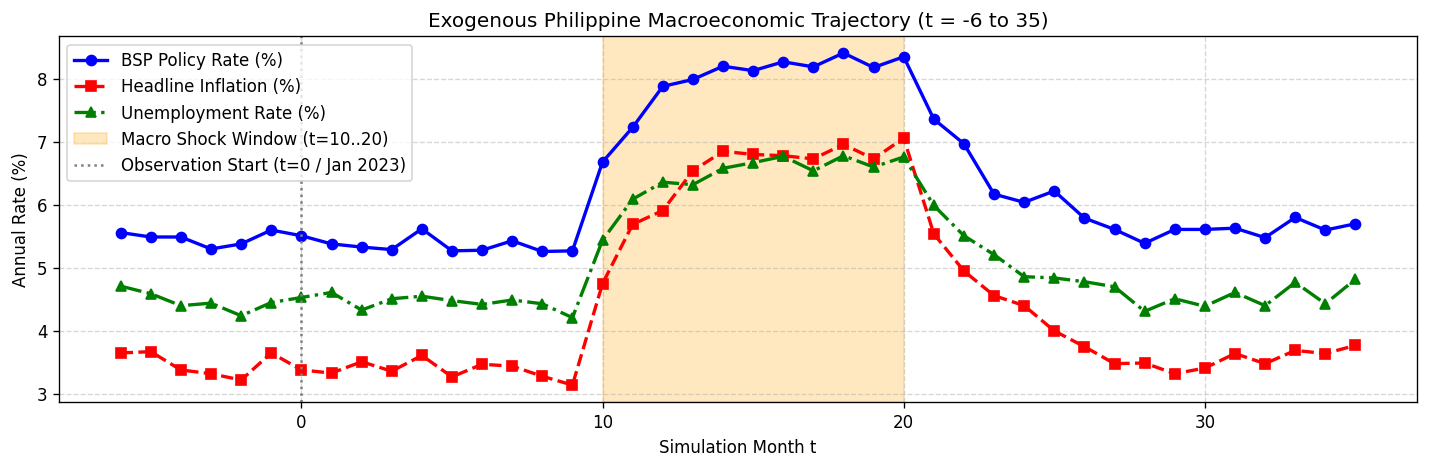

In [2]:
df_macro = generators.generate_macro_series(seed=config.SEED, t_warmup=config.T_WARMUP, t_obs=config.T_OBS)

# Inspect macro series
print("Macro Driver Summary (Head & Tail):")
display(pd.concat([df_macro.head(3), df_macro.tail(3)]))

# Plot Macro Indicators
fig, ax1 = plt.subplots(figsize=(12, 4))
ax1.plot(df_macro['t'], df_macro['r_BSP'] * 100, 'b-o', label='BSP Policy Rate (%)', linewidth=2)
ax1.plot(df_macro['t'], df_macro['headline_inflation'] * 100, 'r--s', label='Headline Inflation (%)', linewidth=2)
ax1.plot(df_macro['t'], df_macro['unemployment_rate'] * 100, 'g-.^', label='Unemployment Rate (%)', linewidth=2)
ax1.axvspan(config.SHOCK_START_T, config.SHOCK_END_T, color='orange', alpha=0.25, label='Macro Shock Window (t=10..20)')
ax1.axvline(0, color='gray', linestyle=':', label='Observation Start (t=0 / Jan 2023)')
ax1.set_xlabel('Simulation Month t')
ax1.set_ylabel('Annual Rate (%)')
ax1.set_title('Exogenous Philippine Macroeconomic Trajectory (t = -6 to 35)')
ax1.grid(True, linestyle='--', alpha=0.5)
ax1.legend(loc='upper left')
plt.tight_layout()
plt.show()

### 3. Stage 1: Borrower Population & Latent Risk Factors
Generates static demographics, socioeconomic categories, and stated income.
Critically, generates unobserved latent traits: **True Cash-Flow Resilience** $U(i) \sim \mathcal{N}(0, 1)$ and **Shadow / Informal Debt Load** $W(i)$ with $\rho(U, W) = -0.35$.

In [3]:
# Select scale: DEFAULT_N_BORROWERS (6,000) or SMOKE_TEST_N_BORROWERS (1,000)
N_RUN = config.DEFAULT_N_BORROWERS  # Set to config.DEFAULT_N_BORROWERS for full 6k production run

df_borrowers = generators.generate_borrowers(n_borrowers=N_RUN, seed=config.SEED)
print(f"Generated {len(df_borrowers):,} borrower profiles.")
display(df_borrowers.head(5))

# Verify Latent Correlation
u_w_corr = df_borrowers['U_resilience'].corr(df_borrowers['W_informal_debt'])
print(f"Empirical Latent Correlation rho(U, W): {u_w_corr:.4f} (Target: {config.RHO_U_W})")

Generated 6,000 borrower profiles.
Empirical Latent Correlation rho(U, W): -0.3520 (Target: -0.35)


,borrower_id,age,region_code,employment_type,employment_tenure_months,stated_monthly_income_php,dependents_count,U_resilience,W_informal_debt
0,BRW-000001,50,NCR,SALARIED_PRIVATE,65.0,46468.87,0,0.496714,-1.217465
1,BRW-000002,21,CENTRAL_LUZON,GOVT_EMPLOYEE,29.0,45093.68,1,-0.138264,-0.542632
2,BRW-000003,35,NCR,SALARIED_PRIVATE,186.0,27448.93,1,0.647689,-1.109166
3,BRW-000004,38,CENTRAL_LUZON,SALARIED_PRIVATE,59.0,87092.31,0,1.523030,-1.046395
4,BRW-000005,38,DAVAO,SALARIED_PRIVATE,58.0,61322.00,4,-0.234153,-0.118652


### 4. Stage 2: Longitudinal CreditScores
Generates quarterly bureau score trajectories with realistic ~6.0% Missing-at-Random (MAR) missingness, credit utilization ratios, and recent inquiry activity.

In [4]:
df_credit_scores = generators.generate_credit_scores(df_borrowers=df_borrowers, df_macro=df_macro, seed=config.SEED)
print(f"Generated {len(df_credit_scores):,} quarterly bureau score observations across 14 quarters.")
display(df_credit_scores.head(5))

bureau_missing_pct = df_credit_scores['bureau_score'].isna().mean() * 100
print(f"Bureau Score Missingness: {bureau_missing_pct:.2f}% (Target: ~6.0% MAR)")

Generated 84,000 quarterly bureau score observations across 14 quarters.
Bureau Score Missingness: 4.18% (Target: ~6.0% MAR)


,score_id,borrower_id,quarter_end_date,bureau_score,credit_utilization_ratio,recent_inquiries_6m
0,SCR-00000001,BRW-000001,2022-09-30,710.0,0.3964,1.0
1,SCR-00000002,BRW-000002,2022-09-30,625.0,0.6486,2.0
2,SCR-00000003,BRW-000003,2022-09-30,696.0,0.3965,1.0
3,SCR-00000004,BRW-000004,2022-09-30,738.0,0.3632,1.0
4,SCR-00000005,BRW-000005,2022-09-30,668.0,0.6085,2.0


### 5. Stages 3 & 4: Loan Contracts and Collateral Registers
Generates loan contracts across 4 product segments with realistic underwriting principal increments (`₱1k` for PERSONAL, `₱10k` for AUTO/SME, `₱50k` for HOUSING).
Secured loans are paired with collateral asset records in `Collateral`.

In [5]:
df_loans = generators.generate_loans(df_borrowers=df_borrowers, seed=config.SEED, t_warmup=config.T_WARMUP, t_obs=config.T_OBS)
df_collateral = generators.generate_collateral(df_loans=df_loans, seed=config.SEED)

print(f"Generated {len(df_loans):,} loan contracts and {len(df_collateral):,} secured collateral records.")
print("\nProduct Mix Distribution:")
print(df_loans['product_type'].value_counts(normalize=True).round(4) * 100)
display(df_loans.head(4))
display(df_collateral.head(4))

Generated 9,927 loan contracts and 5,467 secured collateral records.

Product Mix Distribution:
product_type
PERSONAL    37.80
AUTO        23.98
SME_WC      23.68
HOUSING     14.55
Name: proportion, dtype: float64


,loan_id,borrower_id,product_type,origination_date,term_months,principal_php,initial_apr,rate_type,is_secured,_orig_t,_b_idx
0,LN-000001,BRW-000001,SME_WC,2022-09-01,24,530000.0,0.1553,FLOATING_ANNUAL,True,-4,0
1,LN-000002,BRW-000001,PERSONAL,2022-11-01,12,316000.0,0.2523,FIXED,False,-2,0
2,LN-000003,BRW-000002,PERSONAL,2022-11-01,12,339000.0,0.2746,FIXED,False,-2,1
3,LN-000004,BRW-000003,PERSONAL,2022-10-01,24,322000.0,0.2575,FIXED,False,-3,2


,collateral_id,loan_id,collateral_type,initial_appraised_value_php,origination_ltv,annual_value_drift_rate,expected_haircut_rate,expected_liquidation_months
0,COL-000001,LN-000001,SME_EQUIPMENT_REM,787167.68,0.6733,-0.1056,0.5259,8
1,COL-000002,LN-000005,VEHICLE_CHATTEL,357513.55,0.8671,-0.1344,0.5262,6
2,COL-000003,LN-000006,SME_EQUIPMENT_REM,413109.34,0.7262,-0.1275,0.5224,13
3,COL-000004,LN-000008,VEHICLE_CHATTEL,502813.36,0.8353,-0.1476,0.4458,9


### 6. Stages 5, 6, 7: Monthly Servicing, Payment Ledgers & Delinquency Workouts
Vectorized monthly simulation across all 42 months $t \in [-6, 35]$:
- Level-payment amortization and annual rate repricing for `FLOATING_ANNUAL` facilities.
- Dynamic DTI calculation including shadow debt load and real income inflation erosion.
- Delinquency roll rates and cure probabilities.
- Full early prepayment (SMM/CPR) and partial curtailments.
- Point-in-time IFRS 9 Staging (Stage 1, Stage 2 SICR ratio $\ge 2.0\times$, Stage 3 Default 90+ DPD).
- Collateral liquidation lags and realized LGD workouts.
- Filtering exported `RepaymentSchedules` and `Payments` to the 36-month observation window $t \ge 0$ (2023-01 to 2025-12).

In [6]:
print("Running monthly loan servicing and financial cash-flow simulation...")
df_schedules, df_payments, df_delinquency = generators.simulate_servicing_and_cashflows(
    df_borrowers=df_borrowers,
    df_loans=df_loans,
    df_collateral=df_collateral,
    df_macro=df_macro,
    seed=config.SEED,
    t_warmup=config.T_WARMUP,
    t_obs=config.T_OBS,
)

print(f"Simulation complete:")
print(f"  * RepaymentSchedules: {len(df_schedules):,} monthly records (t >= 0)")
print(f"  * Payments:           {len(df_payments):,} cash flow transactions (t >= 0)")
print(f"  * DelinquencyEvents:  {len(df_delinquency):,} workout/default logs")

# Bundle all tables
tables_raw = {
    "_macro_regime_driver": df_macro,
    "Borrowers": df_borrowers,
    "CreditScores": df_credit_scores,
    "Loans": df_loans,
    "Collateral": df_collateral,
    "RepaymentSchedules": df_schedules,
    "Payments": df_payments,
    "DelinquencyEvents": df_delinquency,
}

Running monthly loan servicing and financial cash-flow simulation...
Simulation complete:
  * RepaymentSchedules: 176,178 monthly records (t >= 0)
  * Payments:           176,178 cash flow transactions (t >= 0)
  * DelinquencyEvents:  1,317 workout/default logs


### 7. Pre-Export Data Integrity & Referential Integrity Checks
Enforces strict relational database constraints across all 7 operational tables:
1. Primary Key Uniqueness & Non-nullability
2. Foreign Key Referential Integrity
3. Balance Non-Negativity and Accounting Consistency
4. IFRS 9 Staging Domain Conformance

In [7]:
# First, strip internal latent variables
tables_scrubbed = validators.scrub_omitted_variables(tables_raw)

# Execute all assertions
integrity_results = validators.run_all_integrity_checks(tables_scrubbed)

print("Data Integrity Assertion Summary:")
for test_name, passed in integrity_results.items():
    status_str = "PASSED [OK]" if passed else "FAILED [!]"
    print(f"  * {test_name:<30}: {status_str}")

Data Integrity Assertion Summary:
  * omitted_variable_scrub        : PASSED [OK]
  * primary_key_uniqueness        : PASSED [OK]
  * foreign_key_integrity         : PASSED [OK]
  * balance_non_negativity        : PASSED [OK]


### 8. Calibration Diagnostics & Open Flags (FLAG-01 through FLAG-05)
Evaluates the five target calibration flags documented in Section 6 of the Research Specifications:
- **FLAG-01:** Cumulative cohort 90+ DPD by product (Personal 8–14%, SME 4–7%, Auto 2–4%, Housing 1–2.5%).
- **FLAG-02:** Monthly 30–59 DPD to 60–89 DPD roll rate (target 25%–40%).
- **FLAG-03:** Annualized Conditional Prepayment Rate (target 6%–14%).
- **FLAG-04:** Stage 2 active loan share during macro shock window $t \in [10, 20]$ (target 8%–18%).
- **FLAG-05:** Observable feature ROC-AUC on 90+ DPD prediction (realistic 0.72–0.82 reflecting omitted variable variance).

In [8]:
diagnostics = validators.evaluate_calibration_flags(tables_scrubbed, df_macro)
validators.print_calibration_report(diagnostics)


 PROJECT SD-186 CALIBRATION & INTEGRITY DIAGNOSTIC REPORT

[FLAG_01] - Cumulative cohort 90+ DPD by product
 Status: PASS
   * PERSONAL: {'total_loans': 3752, 'defaulted_loans': 451, 'default_rate': 0.12020255863539446, 'default_rate_pct': '12.02%'}
   * SME_WC: {'total_loans': 2351, 'defaulted_loans': 142, 'default_rate': 0.0603998298596342, 'default_rate_pct': '6.04%'}
   * AUTO: {'total_loans': 2380, 'defaulted_loans': 88, 'default_rate': 0.03697478991596639, 'default_rate_pct': '3.70%'}
   * HOUSING: {'total_loans': 1444, 'defaulted_loans': 27, 'default_rate': 0.018698060941828253, 'default_rate_pct': '1.87%'}

[FLAG_02] - Monthly 30-59 DPD to 60-89 DPD roll rate (target 25%-40%)
 Status: PASS
   * total_30_59_transitions: 2999
   * rolled_to_60_89_count: 804
   * roll_rate: 0.26808936312104037
   * roll_rate_pct: 26.81%

[FLAG_03] - Annualized CPR (target 6%-14%)
 Status: PASS
   * total_prepaid_principal_php: 441994606.74
   * monthly_smm: 0.0072
   * annualized_cpr: 0.0829
   *

### 9. Pre-Export Scrub Verification & CSV Export
Confirms that all latent traits (`U_resilience`, `W_informal_debt`, `Z_macro_latent`) and internal simulation helpers are scrubbed, and exports exactly the 7 catalog CSVs to `data/raw_export/`.

In [9]:
# Verify omitted variable absence
validators.validate_omitted_variables(tables_scrubbed)
print("Verification Confirmed: Zero prohibited latent or internal variables found in export candidate tables.")

# Export the 7 clean CSV catalog tables
exported_files = validators.export_catalog_tables(tables_raw, export_dir=config.RAW_EXPORT_DIR)

print("\nCatalog Tables Successfully Exported to data/raw_export/:")
for p in exported_files:
    file_size_kb = p.stat().st_size / 1024
    print(f"  - {p.name:<25}: {file_size_kb:>9.1f} KB")

Verification Confirmed: Zero prohibited latent or internal variables found in export candidate tables.
Exported Borrowers.csv: 6,000 rows -> C:\Users\alodi\OneDrive\Desktop\sd186-loan-portfolio\data\raw_export\Borrowers.csv
Exported CreditScores.csv: 84,000 rows -> C:\Users\alodi\OneDrive\Desktop\sd186-loan-portfolio\data\raw_export\CreditScores.csv
Exported Loans.csv: 9,927 rows -> C:\Users\alodi\OneDrive\Desktop\sd186-loan-portfolio\data\raw_export\Loans.csv
Exported Collateral.csv: 5,467 rows -> C:\Users\alodi\OneDrive\Desktop\sd186-loan-portfolio\data\raw_export\Collateral.csv
Exported RepaymentSchedules.csv: 176,178 rows -> C:\Users\alodi\OneDrive\Desktop\sd186-loan-portfolio\data\raw_export\RepaymentSchedules.csv
Exported Payments.csv: 176,178 rows -> C:\Users\alodi\OneDrive\Desktop\sd186-loan-portfolio\data\raw_export\Payments.csv
Exported DelinquencyEvents.csv: 1,317 rows -> C:\Users\alodi\OneDrive\Desktop\sd186-loan-portfolio\data\raw_export\DelinquencyEvents.csv

Catalog Tabl

---
## Next Steps: Notebook 2 (Portfolio EDA & Risk Modeling)
With all 7 tables exported cleanly to `data/raw_export/`:
1. **Vintage Curves:** Cumulative 90+ DPD default curves by origination vintage and MOB.
2. **Delinquency Transition Matrices:** Roll rates across Current, 30–59, 60–89, and 90+ DPD.
3. **Prepayment Curves:** SMM/CPR hazard modeling and rate spread sensitivity.
4. **IFRS 9 Expected Credit Loss:** Staging migration, EAD, LGD discounting, and ECL reserve provisions.
5. **Predictive Risk Modeling:** Logistic Regression and GBDT classification on observed features with realistic omitted-variable variance.